# Báo cáo: Logistic Regression và Softmax Regression trên dữ liệu xe bonbanh.com

Code nằm ở các module `preprocess.py`, `metrics.py`, `logistic_regression.py`, `softmax_regression.py`, `asm1.py`, `asm2.py`, `asm3.py`. Notebook chỉ gọi lại các module và trình bày kết quả.

## Mô tả bài toán

Dữ liệu: ~10.700 tin đăng bán xe cào từ bonbanh.com (`cars_raw.csv`), mỗi xe có hãng, năm sản xuất, số km, dung tích động cơ, số chỗ, nhiên liệu, hộp số, màu, tỉnh, xuất xứ, tình trạng mới/cũ. Sau tiền xử lý mỗi xe là một vector 58 đặc trưng. Cột giá không được dùng làm đặc trưng, chỉ dùng để tạo nhãn.

| | Assignment 1: Logistic Regression | Assignment 2: Softmax Regression |
|---|---|---|
| Bài toán | Nhị phân: xe đắt hay rẻ | Đa lớp: phân khúc giá của xe |
| Nhãn | 1 = giá > median của tập train, 0 = còn lại | 4 lớp theo quartile giá của tập train: rẻ, trung bình, khá, cao cấp |
| Mô hình | $P(\text{đắt}\mid x)=\sigma(w^\top x+b)$ | $P(c\mid x)=\dfrac{e^{z_c}}{\sum_k e^{z_k}},\ z=W^\top x+b$ |
| Loss | binary cross-entropy | categorical cross-entropy |
| Gradient | $\frac1N X^\top(\hat y-y)$ | $\frac1N X^\top(\hat Y-Y)$ |

Cả hai huấn luyện bằng batch Gradient Descent, $w \leftarrow w-\eta\,\nabla L$. Độ đo: precision, recall, F1 tự viết bằng numpy (`metrics.py`).

In [5]:
import os
os.environ["TQDM_DISABLE"] = "1"   # tắt thanh tiến trình cho notebook gọn; log loss theo mốc epoch vẫn in

import numpy as np
import matplotlib.pyplot as plt

from preprocess import prepare_data, CLASS_NAMES_MULTI
from logistic_regression import LogisticRegression
from softmax_regression import SoftmaxRegression
from metrics import print_report, confusion_matrix

## Assignment 1: Logistic Regression (xe đắt/rẻ)

In [6]:
X_train, X_test, y_train, y_test, names = prepare_data("binary", verbose=True)
print("Train:", X_train.shape, "| Test:", X_test.shape, "| số mẫu mỗi lớp (train):", np.bincount(y_train))

logi = LogisticRegression(learning_rate=0.5, epochs=3000)
logi.fit(X_train, y_train, log_every=500)

print(f"\nLoss ban đầu {logi.losses[0]:.4f} -> loss cuối {logi.losses[-1]:.4f}")
print("Loss giảm đơn điệu qua mọi epoch:", bool(np.all(np.diff(logi.losses) <= 1e-9)))

Nhãn nhị phân: 1 = đắt nếu giá > 680 triệu, 0 = rẻ
Train: (8547, 58) | Test: (2137, 58) | số mẫu mỗi lớp (train): [4287 4260]
epoch     0 | loss = 0.6931
epoch   500 | loss = 0.2818
epoch  1000 | loss = 0.2549
epoch  1500 | loss = 0.2436
epoch  2000 | loss = 0.2374
epoch  2500 | loss = 0.2335
epoch  2999 | loss = 0.2308

Loss ban đầu 0.6931 -> loss cuối 0.2308
Loss giảm đơn điệu qua mọi epoch: True


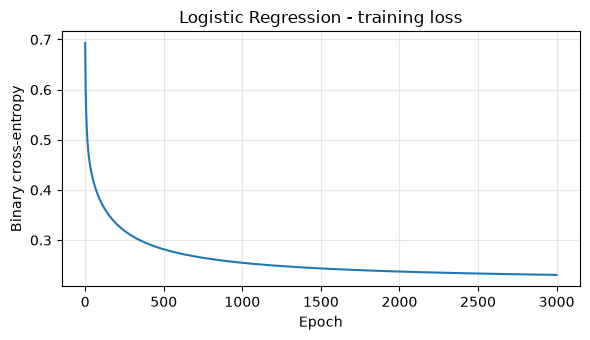

In [7]:
plt.figure(figsize=(6, 3.5))
plt.plot(logi.losses)
plt.xlabel("Epoch"); plt.ylabel("Binary cross-entropy"); plt.title("Logistic Regression - training loss")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [8]:
print("== Test ==")
print_report(logi.evaluate(X_test, y_test))
print("Confusion matrix (hàng = thật, cột = dự đoán; 0 = rẻ, 1 = đắt):")
print(confusion_matrix(y_test, logi.predict(X_test), 2))

== Test ==
  accuracy: 0.9008
 precision: 0.9121
    recall: 0.8864
        f1: 0.8990
Confusion matrix (hàng = thật, cột = dự đoán; 0 = rẻ, 1 = đắt):
[[981  91]
 [121 944]]


## Assignment 2: Softmax Regression (4 phân khúc giá)

In [9]:
X_train2, X_test2, y_train2, y_test2, _ = prepare_data("multi", verbose=True)
print("Số mẫu mỗi lớp (train):", np.bincount(y_train2))

soft = SoftmaxRegression(n_classes=4, learning_rate=0.5, epochs=3000)
soft.fit(X_train2, y_train2, log_every=500)

print(f"\nLoss ban đầu {soft.losses[0]:.4f} -> loss cuối {soft.losses[-1]:.4f}")
print("Loss giảm đơn điệu qua mọi epoch:", bool(np.all(np.diff(soft.losses) <= 1e-9)))

Ngưỡng 4 phân khúc (triệu): {qs[0]:.0f} | {qs[1]:.0f} | {qs[2]:.0f}
Số mẫu mỗi lớp (train): [2121 2134 2154 2138]
epoch     0 | loss = 1.3863
epoch   500 | loss = 0.6373
epoch  1000 | loss = 0.5881
epoch  1500 | loss = 0.5650
epoch  2000 | loss = 0.5512
epoch  2500 | loss = 0.5419
epoch  2999 | loss = 0.5352

Loss ban đầu 1.3863 -> loss cuối 0.5352
Loss giảm đơn điệu qua mọi epoch: True


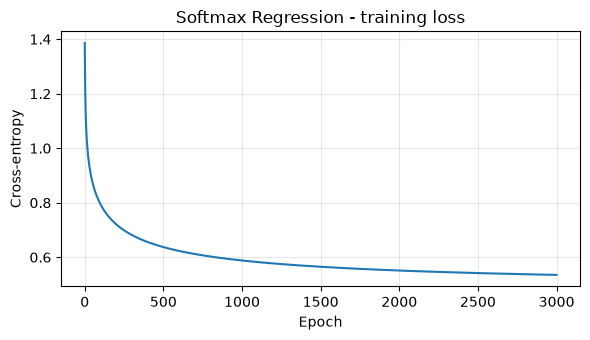

In [10]:
plt.figure(figsize=(6, 3.5))
plt.plot(soft.losses)
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy"); plt.title("Softmax Regression - training loss")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [11]:
print("== Test ==")
print_report(soft.evaluate(X_test2, y_test2, CLASS_NAMES_MULTI))
print("Confusion matrix (hàng = thật, cột = dự đoán; thứ tự: rẻ, trung bình, khá, cao cấp):")
print(confusion_matrix(y_test2, soft.predict(X_test2), 4))

== Test ==
  accuracy: 0.7712
 precision: 0.7711
    recall: 0.7711
        f1: 0.7705
(macro-average; chi tiết từng lớp)
  rẻ           P=0.858  R=0.826  F1=0.842
  trung bình   P=0.656  R=0.692  F1=0.673
  khá          P=0.716  R=0.665  F1=0.690
  cao cấp      P=0.855  R=0.901  F1=0.877
Confusion matrix (hàng = thật, cột = dự đoán; thứ tự: rẻ, trung bình, khá, cao cấp):
[[442  89   2   2]
 [ 64 364  94   4]
 [  6  99 360  76]
 [  3   3  47 482]]


## Assignment 3: so sánh với scikit-learn

In [12]:
from sklearn.linear_model import LogisticRegression as SkLogReg
from sklearn.metrics import accuracy_score, f1_score

sk_bin = SkLogReg(max_iter=1000).fit(X_train, y_train)
sk_mul = SkLogReg(max_iter=1000).fit(X_train2, y_train2)   # đa lớp: sklearn dùng softmax (multinomial)

print(f"{'Mô hình':<34}{'Accuracy':>10}{'F1':>10}")
rows = [
    ("Logistic - numpy (tự cài)",  y_test,  logi.predict(X_test),    "binary"),
    ("Logistic - sklearn",         y_test,  sk_bin.predict(X_test),  "binary"),
    ("Softmax  - numpy (tự cài)",  y_test2, soft.predict(X_test2),   "macro"),
    ("Softmax  - sklearn",         y_test2, sk_mul.predict(X_test2), "macro"),
]
for name, yt, yp, avg in rows:
    print(f"{name:<34}{accuracy_score(yt, yp):>10.4f}{f1_score(yt, yp, average=avg):>10.4f}")

Mô hình                             Accuracy        F1
Logistic - numpy (tự cài)             0.9008    0.8990
Logistic - sklearn                    0.9045    0.9031
Softmax  - numpy (tự cài)             0.7712    0.7705
Softmax  - sklearn                    0.7777    0.7777
